# Speech Emotion Recognition on RAVDESS

**Goal:** classify 8 emotions (neutral, calm, happy, sad, angry, fearful, disgust, surprised) from speech.

**Approach:** compare classical MFCC models, a CNN trained from scratch, and transfer learning with wav2vec2, all evaluated on **speakers the model has never heard**.

**Headline result:** wav2vec2 (layer 4) + logistic regression reaches **73.3% ± 6.8% accuracy** and **0.726 macro F1** in 4-fold speaker-independent cross-validation (chance = 12.5%).

In [ ]:

import numpy as np
import pandas as pd 
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


In [4]:
import glob, os
import pandas as pd

root = "/kaggle/input/datasets/uwrfkaggler/ravdess-emotional-speech-audio"
paths = glob.glob(root + "/**/*.wav", recursive=True)
print("Total files:", len(paths))

emotions = {
    "01": "neutral", "02": "calm", "03": "happy", "04": "sad",
    "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"
}

rows = []
for p in paths:
    parts = os.path.basename(p).replace(".wav", "").split("-")
    rows.append({
        "path": p,
        "emotion": emotions[parts[2]],
        "actor": int(parts[6])
    })

df = pd.DataFrame(rows)
print(df.head())
print(df["emotion"].value_counts())
print("Actors:", df["actor"].nunique())

Total files: 2880
                                                path  emotion  actor
0  /kaggle/input/datasets/uwrfkaggler/ravdess-emo...  neutral      1
1  /kaggle/input/datasets/uwrfkaggler/ravdess-emo...  neutral      1
2  /kaggle/input/datasets/uwrfkaggler/ravdess-emo...  neutral      1
3  /kaggle/input/datasets/uwrfkaggler/ravdess-emo...  neutral      1
4  /kaggle/input/datasets/uwrfkaggler/ravdess-emo...     calm      1
emotion
calm         384
happy        384
sad          384
angry        384
disgust      384
fearful      384
surprised    384
neutral      192
Name: count, dtype: int64
Actors: 24


In [5]:
df["filename"] = df["path"].apply(os.path.basename)
print("Unique filenames:", df["filename"].nunique())

# see which folders the files live in
df["folder"] = df["path"].apply(lambda p: p.split("/ravdess-emotional-speech-audio/")[1].split("/")[0])
print(df["folder"].value_counts())

Unique filenames: 1440
folder
audio_speech_actors_01-24    1440
Actor_02                       60
Actor_03                       60
Actor_04                       60
Actor_05                       60
Actor_06                       60
Actor_07                       60
Actor_08                       60
Actor_01                       60
Actor_09                       60
Actor_10                       60
Actor_12                       60
Actor_11                       60
Actor_14                       60
Actor_15                       60
Actor_16                       60
Actor_13                       60
Actor_17                       60
Actor_18                       60
Actor_20                       60
Actor_19                       60
Actor_21                       60
Actor_22                       60
Actor_23                       60
Actor_24                       60
Name: count, dtype: int64


## 1. Data

RAVDESS speech: 24 actors, 8 emotions, 1,440 clips. Each filename encodes its labels; I used the 3rd field (emotion) and the 7th field (actor ID).

**Data issue found:** the Kaggle copy contained every file twice (2,880 files). I removed duplicates by filename, leaving 1,440 clips (192 per emotion, 96 for neutral). Keeping duplicates would put a clip in both train and test, a form of data leakage that inflates scores.

In [6]:
df = df.drop_duplicates(subset="filename").reset_index(drop=True)
print(len(df))
print(df["emotion"].value_counts())

1440
emotion
calm         192
happy        192
sad          192
angry        192
disgust      192
fearful      192
surprised    192
neutral       96
Name: count, dtype: int64


### Exploring the audio

Clips are about 3.9 seconds at 22,050 samples per second. I plotted waveforms and MFCCs (40 coefficients per time slice) for angry and sad clips: angry speech showed higher average energy in the first MFCC coefficient than sad speech.

angry | samples: 85346 | seconds: 3.87


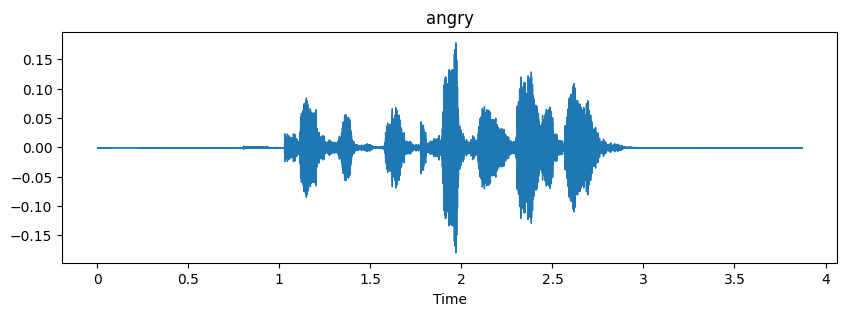

sad | samples: 84610 | seconds: 3.84


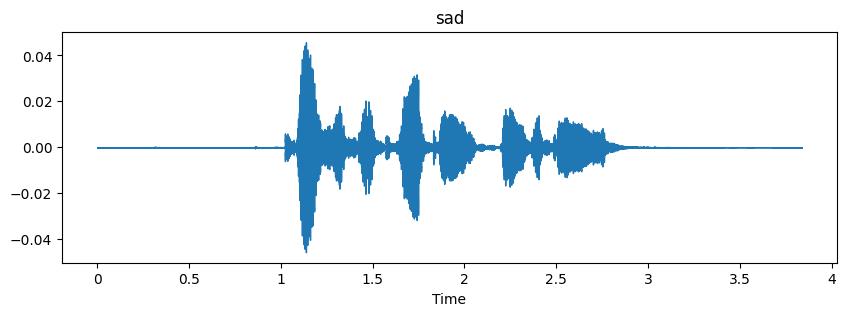

In [7]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd

def show(emotion):
    row = df[df["emotion"] == emotion].iloc[0]
    y, sr = librosa.load(row["path"], sr=22050)
    print(emotion, "| samples:", len(y), "| seconds:", round(len(y)/sr, 2))
    plt.figure(figsize=(10, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(emotion)
    plt.show()
    return ipd.Audio(y, rate=sr)

display(show("angry"))
display(show("sad"))

## 2. Baselines: MFCC features + classical models

Each clip is summarised as the mean and standard deviation of 40 MFCCs over time (80 features).

**Speaker-independent split:** train on actors 1-18, test on actors 19-24. No voice appears in both sets.

| Model | Accuracy | Macro F1 |
|---|---|---|
| Random Forest | 0.406 | 0.360 |
| SVM (RBF) | 0.456 | 0.449 |

Averaging over time discards *when* things happen, which motivates the CNN.

angry | MFCC shape: (40, 167)


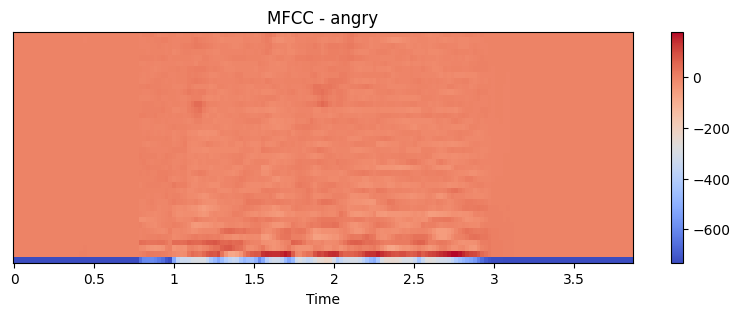

sad | MFCC shape: (40, 166)


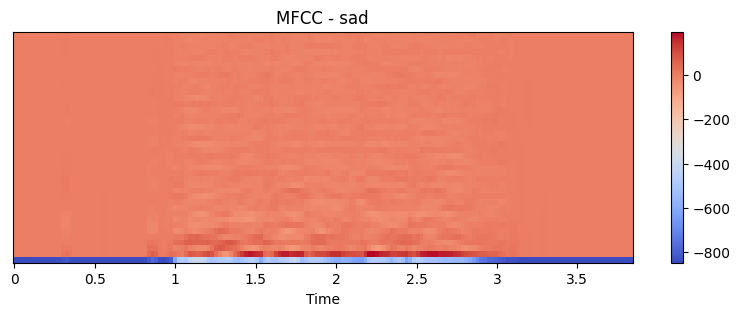

Angry mean (first 5): [-546.1   42.5   -6.    12.6   -1.4]
Sad mean (first 5):   [-680.8   60.8   -2.    14.2    6.8]


In [8]:
import numpy as np

def mfcc_for(emotion):
    row = df[df["emotion"] == emotion].iloc[0]
    y, sr = librosa.load(row["path"], sr=22050)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    print(emotion, "| MFCC shape:", mfcc.shape)
    plt.figure(figsize=(10, 3))
    librosa.display.specshow(mfcc, x_axis="time", sr=sr)
    plt.colorbar()
    plt.title("MFCC - " + emotion)
    plt.show()
    return mfcc

m_angry = mfcc_for("angry")
m_sad = mfcc_for("sad")

# Simple summary: average each coefficient over time -> 40 numbers per clip
print("Angry mean (first 5):", np.round(m_angry.mean(axis=1)[:5], 1))
print("Sad mean (first 5):  ", np.round(m_sad.mean(axis=1)[:5], 1))

Feature matrix: (1440, 80)
Train: (1080, 80) Test: (360, 80)

SVM | accuracy: 0.456 | macro F1: 0.449

Random Forest | accuracy: 0.406 | macro F1: 0.360


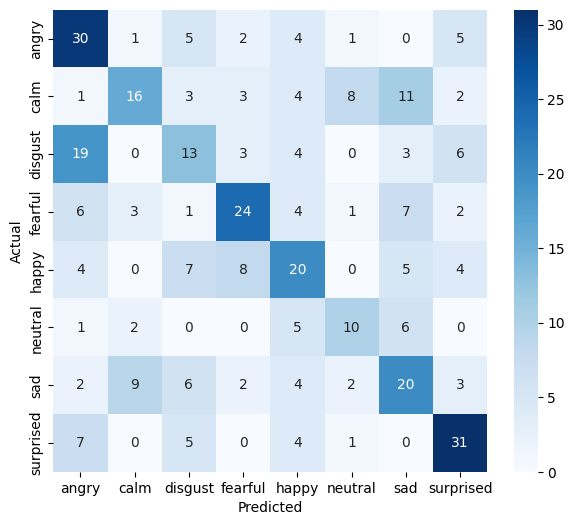

In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import seaborn as sns

# 1. Extract features for every clip
def extract(path):
    y, sr = librosa.load(path, sr=22050)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    return np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)])

X = np.array([extract(p) for p in df["path"]])
labels = df["emotion"].values
print("Feature matrix:", X.shape)   # expect (1440, 80)

# 2. Speaker-independent split
train = df["actor"] <= 18
test = df["actor"] > 18
X_train, X_test = X[train], X[test]
y_train, y_test = labels[train], labels[test]
print("Train:", X_train.shape, "Test:", X_test.shape)

# 3. Scale features (puts all 80 on a similar range)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

# 4. Train two baselines
models = {
    "SVM": SVC(kernel="rbf", C=10),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    print(f"\n{name} | accuracy: {accuracy_score(y_test, pred):.3f} | macro F1: {f1_score(y_test, pred, average='macro'):.3f}")

# 5. Confusion matrix for the SVM
pred = models["SVM"].predict(X_test_s)
names = sorted(set(labels))
cm = confusion_matrix(y_test, pred, labels=names)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=names, yticklabels=names, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [10]:
print(classification_report(y_test, models["SVM"].predict(X_test_s)))

              precision    recall  f1-score   support

       angry       0.43      0.62      0.51        48
        calm       0.52      0.33      0.41        48
     disgust       0.33      0.27      0.30        48
     fearful       0.57      0.50      0.53        48
       happy       0.41      0.42      0.41        48
     neutral       0.43      0.42      0.43        24
         sad       0.38      0.42      0.40        48
   surprised       0.58      0.65      0.61        48

    accuracy                           0.46       360
   macro avg       0.46      0.45      0.45       360
weighted avg       0.46      0.46      0.45       360



In [11]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

MAX_LEN = 200  # time frames; shorter clips are padded, longer ones cut

def mel_for(path):
    y, sr = librosa.load(path, sr=22050)
    m = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
    m = librosa.power_to_db(m)
    if m.shape[1] < MAX_LEN:
        m = np.pad(m, ((0, 0), (0, MAX_LEN - m.shape[1])), constant_values=m.min())
    return m[:, :MAX_LEN]

M = np.array([mel_for(p) for p in df["path"]])
print("Mel array:", M.shape)  # expect (1440, 64, 200)

# normalise using TRAIN statistics only (avoids leaking test info)
mu, sd = M[train.values].mean(), M[train.values].std()
M = (M - mu) / sd

classes = sorted(set(labels))
y_all = np.array([classes.index(l) for l in labels])

def to_loader(mask, shuffle):
    X = torch.tensor(M[mask.values], dtype=torch.float32).unsqueeze(1)  # add channel dim
    y = torch.tensor(y_all[mask.values])
    return DataLoader(TensorDataset(X, y), batch_size=32, shuffle=shuffle)

train_dl, test_dl = to_loader(train, True), to_loader(test, False)

Mel array: (1440, 64, 200)


## 3. CNN on mel-spectrograms (trained from scratch)

| Version | Accuracy | Macro F1 |
|---|---|---|
| v1: basic CNN | 0.347 | 0.241 |
| v2: + silence trimming, per-clip loudness normalisation, SpecAugment, cosine learning-rate decay | 0.450 | 0.366 |

Augmentation helped, but with only 1,080 training clips the CNN still failed on subtle emotions (neutral and sad recall near zero) and did not beat the SVM.

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                         nn.ReLU(), nn.MaxPool2d(2))

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64),
                                      nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(64, 8))
    def forward(self, x):
        return self.head(self.features(x))

model = CNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

def evaluate(dl):
    model.eval(); preds, trues = [], []
    with torch.no_grad():
        for X, y in dl:
            preds += model(X.to(device)).argmax(1).cpu().tolist()
            trues += y.tolist()
    return np.array(preds), np.array(trues)

for epoch in range(1, 41):
    model.train(); total = 0
    for X, y in train_dl:
        X, y = X.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward(); opt.step()
        total += loss.item() * len(y)
    if epoch % 5 == 0:
        p, t = evaluate(test_dl)
        print(f"epoch {epoch} | train loss {total/len(train_dl.dataset):.3f} | test acc {(p==t).mean():.3f}")

p, t = evaluate(test_dl)
print("\nFinal macro F1:", round(f1_score(t, p, average="macro"), 3))
print(classification_report(t, p, target_names=classes))

Device: cuda
epoch 5 | train loss 1.735 | test acc 0.353
epoch 10 | train loss 1.664 | test acc 0.358
epoch 15 | train loss 1.630 | test acc 0.339
epoch 20 | train loss 1.544 | test acc 0.406
epoch 25 | train loss 1.509 | test acc 0.358
epoch 30 | train loss 1.454 | test acc 0.331
epoch 35 | train loss 1.420 | test acc 0.400
epoch 40 | train loss 1.363 | test acc 0.347

Final macro F1: 0.241
              precision    recall  f1-score   support

       angry       0.34      0.79      0.48        48
        calm       0.49      0.71      0.58        48
     disgust       0.26      0.83      0.40        48
     fearful       0.00      0.00      0.00        48
       happy       0.25      0.04      0.07        48
     neutral       0.20      0.04      0.07        24
         sad       0.00      0.00      0.00        48
   surprised       0.83      0.21      0.33        48

    accuracy                           0.35       360
   macro avg       0.30      0.33      0.24       360
weighted 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [13]:
MAX_LEN = 160

def mel_for(path):
    y, sr = librosa.load(path, sr=22050)
    y, _ = librosa.effects.trim(y, top_db=30)          # cut leading/trailing silence
    m = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
    m = librosa.power_to_db(m, ref=np.max)             # loudness normalised per clip
    if m.shape[1] < MAX_LEN:
        m = np.pad(m, ((0, 0), (0, MAX_LEN - m.shape[1])), constant_values=m.min())
    return m[:, :MAX_LEN]

M = np.array([mel_for(p) for p in df["path"]])
mu, sd = M[train.values].mean(), M[train.values].std()
M = (M - mu) / sd
print("Mel array:", M.shape)

train_dl, test_dl = to_loader(train, True), to_loader(test, False)

def augment(X):
    X = X.clone()
    for i in range(X.size(0)):
        X[i] = torch.roll(X[i], np.random.randint(-15, 16), dims=2)   # time shift
        f = np.random.randint(0, 10); f0 = np.random.randint(0, 64 - f)
        X[i, :, f0:f0+f, :] = 0                                       # frequency mask
        t = np.random.randint(0, 20); t0 = np.random.randint(0, X.size(3) - t)
        X[i, :, :, t0:t0+t] = 0                                       # time mask
    return X

torch.manual_seed(42); np.random.seed(42)
model = CNN().to(device)
EPOCHS = 80
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

for epoch in range(1, EPOCHS + 1):
    model.train(); total = 0
    for X, y in train_dl:
        X, y = augment(X).to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward(); opt.step()
        total += loss.item() * len(y)
    sched.step()
    if epoch % 10 == 0:
        p, t = evaluate(test_dl)
        print(f"epoch {epoch} | train loss {total/len(train_dl.dataset):.3f} | test acc {(p==t).mean():.3f}")

p, t = evaluate(test_dl)
print("\nFinal macro F1:", round(f1_score(t, p, average="macro"), 3))
print(classification_report(t, p, target_names=classes))

Mel array: (1440, 64, 160)
epoch 10 | train loss 1.812 | test acc 0.361
epoch 20 | train loss 1.678 | test acc 0.406
epoch 30 | train loss 1.619 | test acc 0.333
epoch 40 | train loss 1.537 | test acc 0.422
epoch 50 | train loss 1.510 | test acc 0.458
epoch 60 | train loss 1.456 | test acc 0.431
epoch 70 | train loss 1.469 | test acc 0.458
epoch 80 | train loss 1.479 | test acc 0.450

Final macro F1: 0.366
              precision    recall  f1-score   support

       angry       0.46      0.56      0.50        48
        calm       0.48      0.81      0.60        48
     disgust       0.39      0.77      0.52        48
     fearful       0.39      0.15      0.21        48
       happy       0.36      0.19      0.25        48
     neutral       0.00      0.00      0.00        24
         sad       0.18      0.08      0.11        48
   surprised       0.65      0.81      0.72        48

    accuracy                           0.45       360
   macro avg       0.36      0.42      0.37     

## 4. Transfer learning: wav2vec2 features

Used the pretrained `facebook/wav2vec2-base` as a frozen feature extractor. Each clip becomes the time-averaged hidden state of each of 13 layers (768 numbers each), and a logistic regression is trained on top.

**Layer selection without leaking the test set:** layers were compared on a validation split (train actors 1-14, validation actors 15-18). Layer 4 scored best (validation macro F1 0.653), while the final layer scored only 0.501. Middle layers keep acoustic detail that emotion depends on.

Single split on test actors 19-24: **accuracy 0.711, macro F1 0.703**.

In [14]:
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model
from sklearn.linear_model import LogisticRegression

name = "facebook/wav2vec2-base"
fe = Wav2Vec2FeatureExtractor.from_pretrained(name)
w2v = Wav2Vec2Model.from_pretrained(name).to(device).eval()

def w2v_feat(path):
    y, _ = librosa.load(path, sr=16000)            # wav2vec2 expects 16 kHz
    y, _ = librosa.effects.trim(y, top_db=30)
    inp = fe(y, sampling_rate=16000, return_tensors="pt")
    with torch.no_grad():
        out = w2v(inp.input_values.to(device), output_hidden_states=True)
    # average over time for each of the 13 layers -> (13, 768)
    return torch.stack([h.mean(1).squeeze(0) for h in out.hidden_states]).cpu().numpy()

F = np.array([w2v_feat(p) for p in df["path"]])
print("Features:", F.shape)   # expect (1440, 13, 768)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

Features: (1440, 13, 768)


In [18]:
np.save("/kaggle/working/w2v_features.npy", F)

## 5. Grouped cross-validation (main result)

A single 6-actor test set is noisy, so I used 4-fold cross-validation grouped by actor: each fold tests on 6 unseen speakers.

| Fold | Accuracy | Macro F1 |
|---|---|---|
| 1 | 0.803 | 0.793 |
| 2 | 0.689 | 0.677 |
| 3 | 0.794 | 0.794 |
| 4 | 0.644 | 0.641 |
| **Mean ± std** | **0.733 ± 0.068** | **0.726 ± 0.069** |

Results vary by speaker group, so the mean ± std is more trustworthy than any single split.

*Limitation:* layer 4 was chosen using actors 15-18, who appear in some test folds, so the estimate is slightly optimistic.

In [15]:
tr = (df["actor"] <= 14).values
va = ((df["actor"] > 14) & (df["actor"] <= 18)).values

best_layer, best_f1 = None, 0
for layer in range(13):
    sc = StandardScaler().fit(F[tr, layer])
    clf = LogisticRegression(max_iter=2000).fit(sc.transform(F[tr, layer]), labels[tr])
    f1 = f1_score(labels[va], clf.predict(sc.transform(F[va, layer])), average="macro")
    print(f"layer {layer:2d} | validation macro F1 {f1:.3f}")
    if f1 > best_f1: best_layer, best_f1 = layer, f1

print("\nChosen layer:", best_layer)

# Final: train on actors 1-18, test ONCE on actors 19-24
trn, tst = train.values, test.values
sc = StandardScaler().fit(F[trn, best_layer])
clf = LogisticRegression(max_iter=2000).fit(sc.transform(F[trn, best_layer]), labels[trn])
pred = clf.predict(sc.transform(F[tst, best_layer]))
print("Test accuracy:", round(accuracy_score(labels[tst], pred), 3),
      "| macro F1:", round(f1_score(labels[tst], pred, average="macro"), 3))
print(classification_report(labels[tst], pred))

layer  0 | validation macro F1 0.480
layer  1 | validation macro F1 0.561
layer  2 | validation macro F1 0.622
layer  3 | validation macro F1 0.645
layer  4 | validation macro F1 0.653
layer  5 | validation macro F1 0.636
layer  6 | validation macro F1 0.619
layer  7 | validation macro F1 0.594
layer  8 | validation macro F1 0.614
layer  9 | validation macro F1 0.620
layer 10 | validation macro F1 0.613
layer 11 | validation macro F1 0.591
layer 12 | validation macro F1 0.501

Chosen layer: 4
Test accuracy: 0.711 | macro F1: 0.703
              precision    recall  f1-score   support

       angry       0.83      0.81      0.82        48
        calm       0.61      0.79      0.69        48
     disgust       0.87      0.83      0.85        48
     fearful       0.85      0.58      0.69        48
       happy       0.84      0.54      0.66        48
     neutral       0.56      0.58      0.57        24
         sad       0.51      0.62      0.56        48
   surprised       0.72      0

## 6. Error analysis

Confusion matrix on test actors 19-24:

- Strongest: surprised, disgust, angry, calm.
- Largest confusions: **fearful → sad (16)**, **sad → calm (11)**, **happy → surprised (8)**, **calm ↔ neutral**.
- Errors mostly stay within the same arousal level (low: calm/neutral/sad; high: angry/happy/surprised). The model captures *how intense* the speech is better than *whether it is positive or negative*.

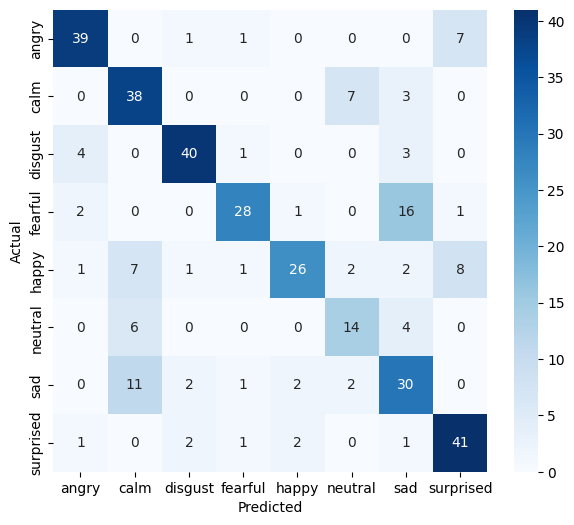

In [19]:
cm = confusion_matrix(labels[tst], pred, labels=classes)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [20]:
from sklearn.model_selection import GroupKFold

X4 = F[:, 4]                       # layer 4 features
gkf = GroupKFold(n_splits=4)       # 4 folds x 6 actors each
accs, f1s = [], []

for fold, (tr_i, te_i) in enumerate(gkf.split(X4, labels, groups=df["actor"]), 1):
    sc = StandardScaler().fit(X4[tr_i])
    clf = LogisticRegression(max_iter=2000).fit(sc.transform(X4[tr_i]), labels[tr_i])
    p = clf.predict(sc.transform(X4[te_i]))
    a, f = accuracy_score(labels[te_i], p), f1_score(labels[te_i], p, average="macro")
    accs.append(a); f1s.append(f)
    print(f"fold {fold} | test actors {sorted(df['actor'].iloc[te_i].unique())} | acc {a:.3f} | macro F1 {f:.3f}")

print(f"\nMean accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f}")
print(f"Mean macro F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")

fold 1 | test actors [np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20), np.int64(24)] | acc 0.803 | macro F1 0.793
fold 2 | test actors [np.int64(3), np.int64(7), np.int64(11), np.int64(15), np.int64(19), np.int64(23)] | acc 0.689 | macro F1 0.677
fold 3 | test actors [np.int64(2), np.int64(6), np.int64(10), np.int64(14), np.int64(18), np.int64(22)] | acc 0.794 | macro F1 0.794
fold 4 | test actors [np.int64(1), np.int64(5), np.int64(9), np.int64(13), np.int64(17), np.int64(21)] | acc 0.644 | macro F1 0.641

Mean accuracy 0.733 ± 0.068
Mean macro F1 0.726 ± 0.069


In [21]:
import joblib

sc_final = StandardScaler().fit(F[:, 4])
clf_final = LogisticRegression(max_iter=2000).fit(sc_final.transform(F[:, 4]), labels)
joblib.dump({"scaler": sc_final, "clf": clf_final, "layer": 4}, "/kaggle/working/emotion_model.joblib")
print("Saved. Classes:", list(clf_final.classes_))

Saved. Classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']


## 7. Experiment: prosody features (no gain)

I added 8 hand-crafted prosody features (energy variation, spectral centroid, zero-crossing rate, pitch level, variation and range) to the wav2vec2 features.

| Features | Macro F1 | Angry recall |
|---|---|---|
| wav2vec2 only | 0.726 ± 0.069 | 0.807 |
| wav2vec2 + prosody | 0.729 ± 0.072 | 0.807 |

The difference is within noise, so wav2vec2 already captures this information. The final model uses wav2vec2 features only.

In [24]:
def prosody(path):
    y, _ = librosa.load(path, sr=16000)
    y = clean(y)
    rms = librosa.feature.rms(y=y)[0]
    cent = librosa.feature.spectral_centroid(y=y, sr=16000)[0]
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    f0 = librosa.yin(y, fmin=65, fmax=400, sr=16000)
    return np.array([
        rms.std() / rms.mean(),                    # how much energy varies
        rms.max() / rms.mean(),                    # how peaky the loudness is
        cent.mean(), cent.std(),                   # brightness of the sound
        zcr.mean(),                                # noisiness
        f0.mean(), f0.std(),                       # pitch level and variation
        np.percentile(f0, 90) - np.percentile(f0, 10),  # pitch range
    ])

P = np.array([prosody(p) for p in df["path"]])
print("Prosody:", P.shape)   # expect (1440, 8)

def run_cv(X):
    all_pred = np.empty(len(labels), dtype=object); f1s = []
    for tr_i, te_i in GroupKFold(n_splits=4).split(X, labels, groups=df["actor"]):
        sc = StandardScaler().fit(X[tr_i])
        clf = LogisticRegression(max_iter=3000).fit(sc.transform(X[tr_i]), labels[tr_i])
        all_pred[te_i] = clf.predict(sc.transform(X[te_i]))
        f1s.append(f1_score(labels[te_i], all_pred[te_i], average="macro"))
    print(f"macro F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f} | angry recall {(all_pred[labels=='angry']=='angry').mean():.3f}")

print("wav2vec2 only:      ", end=""); run_cv(F[:, 4])
print("wav2vec2 + prosody: ", end=""); run_cv(np.hstack([F[:, 4], P]))

Prosody: (1440, 8)
wav2vec2 only:      macro F1 0.726 ± 0.069 | angry recall 0.807
wav2vec2 + prosody: macro F1 0.729 ± 0.072 | angry recall 0.807


## 8. Demo and real-world test

A Gradio app takes an uploaded or recorded clip and returns emotion probabilities. Silent gaps are removed before feature extraction.

**Informal real-world test (my own voice, a few clips):** removing silence fixed several emotions, but angry speech was predicted as neutral or happy. This is *domain shift*: the model learned from 24 acted, studio-quality, North American speech recordings with two sentences. These tests are anecdotal and not part of the reported results.

In [23]:
!pip -q install gradio
import gradio as gr

def clean(y, top_db=25):
    intervals = librosa.effects.split(y, top_db=top_db)
    return np.concatenate([y[s:e] for s, e in intervals]) if len(intervals) else y

def predict(audio_path):
    if audio_path is None:
        return {}
    y, _ = librosa.load(audio_path, sr=16000)
    print("original seconds:", round(len(y)/16000, 2))
    y = clean(y)
    print("after removing silence:", round(len(y)/16000, 2))
    inp = fe(y, sampling_rate=16000, return_tensors="pt")
    with torch.no_grad():
        out = w2v(inp.input_values.to(device), output_hidden_states=True)
    feat = out.hidden_states[4].mean(1).squeeze(0).cpu().numpy().reshape(1, -1)
    probs = clf_final.predict_proba(sc_final.transform(feat))[0]
    return {c: float(p) for c, p in zip(clf_final.classes_, probs)}

demo = gr.Interface(fn=predict, inputs=gr.Audio(type="filepath"),
                    outputs=gr.Label(num_top_classes=8))
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://3a9973a95405e3433a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


original seconds: 4.38
after removing silence: 1.7
original seconds: 5.1
after removing silence: 2.05
original seconds: 4.68
after removing silence: 3.23
original seconds: 3.96
after removing silence: 2.24
original seconds: 4.32
after removing silence: 1.98
original seconds: 4.08
after removing silence: 1.54
original seconds: 4.86
after removing silence: 1.5
original seconds: 4.74
after removing silence: 1.95
original seconds: 3.54
after removing silence: 1.44


In [26]:
import hashlib

def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

all_df = pd.DataFrame({"path": paths})
all_df["filename"] = all_df["path"].apply(os.path.basename)
all_df["hash"] = all_df["path"].apply(md5)

# for each filename, how many different file contents exist?
print(all_df.groupby("filename")["hash"].nunique().value_counts())

hash
1    1440
Name: count, dtype: int64
